In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from scipy.stats import shapiro, t

Obtener datos Grupo Control

In [2]:
# Obtener datos de grupo control

'https://docs.google.com/spreadsheets/d/1hLxzLvhqROPelBWYukI6BLQLRNKlE3G5/edit?gid=866666347#gid=866666347'
sheet_id = "1hLxzLvhqROPelBWYukI6BLQLRNKlE3G5"
gid = "866666347"
url = f"https://docs.google.com/spreadsheets/d/{sheet_id}/export?format=xlsx&gid={gid}"
file = pd.read_excel(url)
grupo_control = file[file["Grupo"] == 'Control']
grupo_control = grupo_control.drop(columns=['Marca temporal', 'Nombre'])

grupo_control.head()

,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
60,Control,Pretest,1,2,3,2,1,3,4,1,1,1,3,4,4,1,1,3,5,1
61,Control,Postest,1,2,4,5,3,1,3,1,2,1,4,3,5,4,3,3,2,3
62,Control,Pretest,2,3,4,2,2,2,3,2,3,2,5,3,2,2,3,2,5,2
63,Control,Postest,1,2,3,3,2,3,1,4,2,3,2,3,2,2,3,1,2,2
64,Control,Pretest,2,3,2,2,2,3,5,2,3,5,2,2,3,5,2,2,1,1


Obtener datos Grupo Experimental

In [3]:
'https://docs.google.com/spreadsheets/d/1XE4HPULK9j5NMOfBo1lkc_UlcT1F9_vT/edit?gid=1421523016#gid=1421523016'
id_sheet = '1XE4HPULK9j5NMOfBo1lkc_UlcT1F9_vT'
gid = '1421523016'
url = f'https://docs.google.com/spreadsheets/d/{id_sheet}/export?format=xlsx&gid={gid}'
file = pd.read_excel(url)
file.head()

,Marca temporal,Marca temporal 2,Marca temporal 3,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,...,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
0,2026-09-26 15:01:21.553,2026-09-26 15:01:21.553,2026-09-26 15:01:21.553,Pretest,2 a veces,2 a veces,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,...,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,2 a veces,2 a veces,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia,3 con cierta frecuencia
1,2026-09-26 15:03:20.684,2026-09-26 15:03:20.684,2026-09-26 15:03:20.684,Postest,2 a veces,2 a veces,4 muy frecuentemente,1 nunca,2 a veces,2 a veces,...,2 a veces,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,3 con cierta frecuencia
2,2026-09-26 15:05:26.455,2026-09-26 15:05:26.455,2026-09-26 15:05:26.455,Pretest,1 nunca,5 casi siempre,2 a veces,5 casi siempre,1 nunca,2 a veces,...,1 nunca,1 nunca,1 nunca,2 a veces,1 nunca,5 casi siempre,3 con cierta frecuencia,4 muy frecuentemente,2 a veces,1 nunca
3,2026-09-26 15:06:43.350,2026-09-26 15:06:43.350,2026-09-26 15:06:43.350,Postest,3 con cierta frecuencia,5 casi siempre,4 muy frecuentemente,5 casi siempre,2 a veces,3 con cierta frecuencia,...,1 nunca,1 nunca,2 a veces,5 casi siempre,2 a veces,4 muy frecuentemente,3 con cierta frecuencia,2 a veces,3 con cierta frecuencia,5 casi siempre
4,2026-09-26 15:08:55.322,2026-09-26 15:08:55.322,2026-09-26 15:08:55.322,Pretest,1 nunca,3 con cierta frecuencia,5 casi siempre,2 a veces,2 a veces,3 con cierta frecuencia,...,2 a veces,1 nunca,5 casi siempre,5 casi siempre,1 nunca,3 con cierta frecuencia,3 con cierta frecuencia,2 a veces,5 casi siempre,1 nunca


In [4]:
# Limpiar grupo experimental

# Eliminar marcas temporales
grupo_experimental = file.drop(columns=["Marca temporal", "Marca temporal 2", "Marca temporal 3"])

# Agregar columna grupo con el valor experimental por defecto y posicionar en la primera columna
grupo_experimental['Grupo'] = "Experimental"
grupo_experimental.insert(0, 'Grupo', grupo_experimental.pop('Grupo'))

# Reemplazar valores
reemplazar_valores = {
    "1 nunca": 1,
    "2 a veces": 2,
    "3 con cierta frecuencia": 3,
    "4 muy frecuentemente": 4,
    "5 casi siempre": 5,
}
for column in grupo_experimental.columns:
    grupo_experimental[column] = grupo_experimental[column].replace(reemplazar_valores)

grupo_experimental.head()

C:\Users\crist\AppData\Local\Temp\ipykernel_21620\402643191.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  grupo_experimental[column] = grupo_experimental[column].replace(reemplazar_valores)


,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
0,Experimental,Pretest,2,2,3,2,3,2,3,3,3,2,3,2,2,2,2,3,3,3
1,Experimental,Postest,2,2,4,1,2,2,2,2,2,2,3,3,3,2,3,2,3,3
2,Experimental,Pretest,1,5,2,5,1,2,2,1,1,1,1,2,1,5,3,4,2,1
3,Experimental,Postest,3,5,4,5,2,3,4,1,1,1,2,5,2,4,3,2,3,5
4,Experimental,Pretest,1,3,5,2,2,3,5,1,2,1,5,5,1,3,3,2,5,1


**Aplicar instrumento conflictalk

In [5]:
# Unir los datos del grupo experimental y control
datos_conflictalk = pd.concat([grupo_control, grupo_experimental])
datos_conflictalk

,Grupo,Test,1. ¿No te das cuenta de lo estúpido que eres?,"2. No se me da bien esto. Simplemente, no sé cómo hacer que te sientas mejor.",3. ¿Qué está pasando? Necesitamos hablar.,4. No te sirvo de ayuda. Nunca sé qué decir.,5. Tenemos que concretar eso.,6. Quisiera que pudieramos evitar todo este asunto.,7. Vamos a hablar sobre esto y encontrar una solución.,8. ¡Cállate! ¡No tienes razón! No voy a escucharte,9. ¡Es tu culpa tuya! Y no voy a ayudarte,10. Harás lo que yo te digo. ¡Te voy a obligar!,11. Funcionará si trabajamos juntos.,12. Trabajaremos para sacar esto adelante.,"13. De acuerdo, me rindo, lo que tú quieras.",14. No quiero hacer esto nunca más. Vamos cada uno por su lado.,"15. Esto no va a ninguna parte, olvidemos todo el asunto. ¿de acuerdo?","16. Si no quieres hacerlo, olvídalo; ya se lo pediré a algún otro.",17. Necesitamos concretar juntos cuál es el problema.,18. No puedes hacer nada. Apártate de mi camino y déjame hacerlo.
60,Control,Pretest,1,2,3,2,1,3,4,1,1,1,3,4,4,1,1,3,5,1
61,Control,Postest,1,2,4,5,3,1,3,1,2,1,4,3,5,4,3,3,2,3
62,Control,Pretest,2,3,4,2,2,2,3,2,3,2,5,3,2,2,3,2,5,2
63,Control,Postest,1,2,3,3,2,3,1,4,2,3,2,3,2,2,3,1,2,2
64,Control,Pretest,2,3,2,2,2,3,5,2,3,5,2,2,3,5,2,2,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55,Experimental,Postest,3,2,1,1,3,2,4,2,1,1,3,5,3,2,1,3,3,2
56,Experimental,Pretest,3,3,2,1,1,3,2,1,2,1,3,2,2,1,1,1,1,2
57,Experimental,Postest,2,2,2,2,2,2,2,1,3,1,3,2,3,3,2,2,3,1
58,Experimental,Pretest,1,3,4,3,4,5,5,1,1,1,4,4,2,2,3,1,4,1


In [6]:

estilos = {
    "cooperativo": [3, 5, 7, 11, 12, 17],
    "evitativo": [2, 4, 6, 13, 14, 15],
    "agresivo": [1, 8, 9, 10, 16, 18]
}

for estilo in estilos:
    # dar con la columnas correspondiente real
    x = [i+1 for i in estilos[estilo]]
    
    # Sumar columnas correspondientes
    datos_conflictalk[estilo] = datos_conflictalk.iloc[:, x].sum(axis=1)

datos_estilos = datos_conflictalk[['Grupo', 'Test'] + list(estilos)].copy()
datos_estilos

,Grupo,Test,cooperativo,evitativo,agresivo
60,Control,Pretest,20,13,8
61,Control,Postest,19,20,11
62,Control,Pretest,22,14,13
63,Control,Postest,13,15,13
64,Control,Pretest,14,18,15
...,...,...,...,...,...
55,Experimental,Postest,19,11,12
56,Experimental,Pretest,11,11,10
57,Experimental,Postest,14,14,10
58,Experimental,Pretest,25,18,6


Estadísticos descriptivos

In [7]:
tabla_descriptivos = datos_estilos.groupby(['Grupo', 'Test'])[list(estilos.keys())].agg(['count', 'mean', 'std' ]).round(2)
tabla_descriptivos

cooperativo              evitativo              agresivo  \
                           count   mean   std     count   mean   std    count   
Grupo        Test                                                               
Control      Postest          30  17.77  5.96        30  14.53  5.27       30   
             Pretest          30  17.43  5.33        30  14.30  4.63       30   
Experimental Postest          30  16.33  4.12        30  13.60  4.01       30   
             Pretest          30  16.67  4.96        30  13.57  4.51       30   

                                   
                       mean   std  
Grupo        Test                  
Control      Postest  11.90  4.82  
             Pretest  12.50  4.54  
Experimental Postest  10.37  3.68  
             Pretest  10.33  3.89

In [8]:
# Aplanar el MultiIndex de columnas
tabla_plot = tabla_descriptivos.copy()
tabla_plot.columns = ['_'.join(col) for col in tabla_plot.columns]
tabla_plot = tabla_plot.reset_index()

# Pasar a formato largo (una fila por Grupo, Test, Estilo)
tabla_long = tabla_plot.melt(
    id_vars=['Grupo', 'Test'],
    value_vars=['cooperativo_mean', 'evitativo_mean', 'agresivo_mean'],
    var_name='Estilo',
    value_name='Promedio'
)
tabla_long['Estilo'] = tabla_long['Estilo'].str.replace('_mean', '')

#
colores = {
    'cooperativo': "#3E3298",
    'evitativo': "#6958EA",
    'agresivo': "#0B0444"
}



In [9]:
fig = px.bar(
    tabla_long,
    x='Grupo',
    y='Promedio',
    color='Estilo',
    barmode='group',
    facet_col='Test',  # una faceta por Control/Experimental
    title='Promedio de estilos de conflicto por grupo',
    color_discrete_map=colores,
    category_orders={
        'Test': ['Pretest', "Postest"]
    }
)
fig.show()

In [10]:
fig = px.bar(
    tabla_long,
    x='Test',
    y='Promedio',
    color='Estilo',
    barmode='group',
    facet_col='Grupo',  # una faceta por Control/Experimental
    title='Promedio de estilos de conflicto por grupo',
    color_discrete_map=colores,
    category_orders={
        'Test': ['Pretest', "Postest"]
    }
)
fig.show()

In [11]:
tabla_diff_grupo = tabla_long.pivot_table(
    index=['Grupo', 'Estilo'],
    columns='Test',
    values='Promedio'
).reset_index()

tabla_diff_grupo['Diferencia'] = tabla_diff_grupo['Postest'] - tabla_diff_grupo['Pretest']

tabla_diff_grupo = tabla_diff_grupo[['Grupo', 'Estilo', 'Pretest', 'Postest', 'Diferencia']]

tabla_diff_grupo

Test,Grupo,Estilo,Pretest,Postest,Diferencia
0,Control,agresivo,12.50,11.90,-0.60
1,Control,cooperativo,17.43,17.77,0.34
2,Control,evitativo,14.30,14.53,0.23
3,Experimental,agresivo,10.33,10.37,0.04
4,Experimental,cooperativo,16.67,16.33,-0.34
5,Experimental,evitativo,13.57,13.60,0.03


In [12]:
# Ordenar la categoria del test
tabla_long['Test'] = pd.Categorical(
    tabla_long['Test'],
    categories=['Pretest', 'Postest'],
    ordered=True
)

tabla_diff_test = tabla_long.pivot_table(
    index=['Test', 'Estilo'],
    columns='Grupo',
    values='Promedio'
).reset_index()

tabla_diff_test['Diferencia'] = tabla_diff_test['Experimental'] - tabla_diff_test['Control']

tabla_diff_test = tabla_diff_test[['Test', 'Estilo', 'Control', 'Experimental', 'Diferencia']]

tabla_diff_test

C:\Users\crist\AppData\Local\Temp\ipykernel_21620\1608946572.py:8: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



Grupo,Test,Estilo,Control,Experimental,Diferencia
0,Pretest,agresivo,12.50,10.33,-2.17
1,Pretest,cooperativo,17.43,16.67,-0.76
2,Pretest,evitativo,14.30,13.57,-0.73
3,Postest,agresivo,11.90,10.37,-1.53
4,Postest,cooperativo,17.77,16.33,-1.44
5,Postest,evitativo,14.53,13.60,-0.93


In [13]:
fig = px.bar(
    tabla_diff_test,
    x='Estilo',
    y='Diferencia',
    color='Estilo',
    facet_col='Test',
    color_discrete_map=colores,
    category_orders={
        'Estilo': estilos.keys()
    }
)
fig.add_hline(y=0, line_dash='dash', line_color='gray')
fig.update_layout(showlegend=False)
fig.show()

In [14]:
fig = px.bar(
    tabla_diff_grupo,
    x='Estilo',
    y='Diferencia',
    color='Estilo',
    facet_col='Grupo',
    color_discrete_map=colores,
    category_orders={
        'Estilo': estilos.keys()
    }
)
fig.add_hline(y=0, line_dash='dash', line_color='gray')
fig.update_layout(showlegend=False)
fig.show()

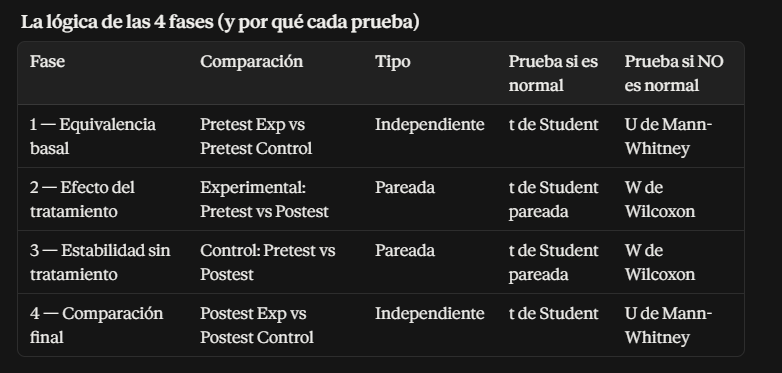

# 1. Equivalencia <br>
**Comparación**: Pretest (Control | Experimental) <br>
**Intención:** Verificar que los 2 grupos partan desde las mismas condiciones

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal

In [15]:
tabla_datos = datos_estilos.melt(
    id_vars=[
        'Grupo', 
        'Test'
    ],
    value_vars=['cooperativo', 'evitativo', 'agresivo'],
    var_name='Estilo',
    value_name='Puntaje'
)
# Ordenar categorias
tabla_datos['Estilo'] = pd.Categorical(
    tabla_datos['Estilo'],
    categories=['cooperativo', 'evitativo', 'agresivo'],
)
tabla_datos['Test'] = pd.Categorical(
    tabla_datos['Test'],
    categories=['Pretest', 'Postest'],
)
tabla_datos['Grupo'] = pd.Categorical(
    tabla_datos['Grupo'],
    categories=['Experimental', 'Control'],
)

In [16]:
from scipy.stats import shapiro, t

alpha = 0.05

# Filtrar únicamente el Grupo Experimental
datos_experimental = tabla_datos[
    tabla_datos['Grupo']
    .astype(str)
    .str.strip()
    .str.lower()
    .eq('experimental')
].copy()

# Normalizar nombres de las categorías
datos_experimental['Estilo'] = (
    datos_experimental['Estilo'].astype(str).str.strip().str.lower()
)

datos_experimental['Test'] = (
    datos_experimental['Test'].astype(str).str.strip().str.lower()
)

# Convertir puntajes a valores numéricos
datos_experimental['Puntaje'] = pd.to_numeric(
    datos_experimental['Puntaje'],
    errors='coerce'
)

resultados = []

# Agrupar por Estilo y momento de evaluación
for (estilo, test), grupo in datos_experimental.groupby(
    ['Estilo', 'Test'],
    observed=True
):

    datos = grupo['Puntaje'].dropna().to_numpy()

    N = len(datos)

    # Estadísticos descriptivos
    media = np.mean(datos) if N > 0 else np.nan

    desviacion = (
        np.std(datos, ddof=1)
        if N >= 2
        else np.nan
    )

    # Calcular Shapiro-Wilk
    if N >= 3:
        resultado_shapiro = shapiro(datos)
        W = resultado_shapiro.statistic
        pvalue = resultado_shapiro.pvalue
    else:
        W = np.nan
        pvalue = np.nan

    # Calcular IC del 95 % para la media
    if N >= 2:

        gl = N - 1

        t_critico = t.ppf(
            1 - alpha / 2,
            gl
        )

        error_estandar = desviacion / np.sqrt(N)

        margen_error = t_critico * error_estandar

        ic_inferior = media - margen_error
        ic_superior = media + margen_error

    else:
        ic_inferior = np.nan
        ic_superior = np.nan

    # Decisión de normalidad
    if pd.isna(pvalue):
        decision = 'No calculable'
        distribucion = 'No determinada'

    elif pvalue > alpha:
        decision = 'No se rechaza H₀'
        distribucion = 'Compatible con normalidad'

    else:
        decision = 'Se rechaza H₀'
        distribucion = 'Evidencia de no normalidad'

    # Guardar resultados
    resultados.append({
        'Estilo': estilo.capitalize(),
        'Grupo': 'Experimental',
        'Test': test.capitalize(),
        'N': N,
        'Prueba': 'Shapiro-Wilk',
        'media': media,
        'desviacion_estandar': desviacion,
        'IC 95% inferior': ic_inferior,
        'IC 95% superior': ic_superior,
        'α': alpha,
        'pvalue': pvalue,
        'W': W,
        'Resultado hipótesis': decision,
        'Distribución': distribucion
    })


# Crear DataFrame
tabla_normalidad = pd.DataFrame(resultados)

# Ordenar los resultados
orden_test = pd.CategoricalDtype(
    categories=['Pretest', 'Postest'],
    ordered=True
)

tabla_normalidad['Test'] = tabla_normalidad['Test'].astype(orden_test)

tabla_normalidad = tabla_normalidad.sort_values(
    ['Estilo', 'Test']
).reset_index(drop=True)


# Mostrar tabla
tabla_normalidad.style.format({
    'media': '{:.3f}',
    'desviacion_estandar': '{:.3f}',
    'IC 95% inferior': '{:.3f}',
    'IC 95% superior': '{:.3f}',
    'α': '{:.2f}',
    'pvalue': '{:.4f}',
    'W': '{:.4f}'
})

,Estilo,Grupo,Test,N,Prueba,media,desviacion_estandar,IC 95% inferior,IC 95% superior,α,pvalue,W,Resultado hipótesis,Distribución
0,Agresivo,Experimental,Pretest,30,Shapiro-Wilk,10.333,3.889,8.881,11.786,0.05,0.0005,0.8473,Se rechaza H₀,Evidencia de no normalidad
1,Agresivo,Experimental,Postest,30,Shapiro-Wilk,10.367,3.681,8.992,11.741,0.05,0.0009,0.8580,Se rechaza H₀,Evidencia de no normalidad
2,Cooperativo,Experimental,Pretest,30,Shapiro-Wilk,16.667,4.964,14.813,18.520,0.05,0.6180,0.9728,No se rechaza H₀,Compatible con normalidad
3,Cooperativo,Experimental,Postest,30,Shapiro-Wilk,16.333,4.122,14.794,17.872,0.05,0.5254,0.9695,No se rechaza H₀,Compatible con normalidad
4,Evitativo,Experimental,Pretest,30,Shapiro-Wilk,13.567,4.508,11.883,15.250,0.05,0.5134,0.9690,No se rechaza H₀,Compatible con normalidad
5,Evitativo,Experimental,Postest,30,Shapiro-Wilk,13.600,4.005,12.104,15.096,0.05,0.4141,0.9651,No se rechaza H₀,Compatible con normalidad


In [17]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import norm, shapiro
import numpy as np

# Categorías
estilos = ['cooperativo', 'evitativo', 'agresivo']
grupos = ['Control', 'Experimental']

# Filtrar únicamente Pretest
pretest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'pretest'
].copy()

# Normalizar categorías
pretest['Estilo'] = (
    pretest['Estilo'].astype(str).str.strip().str.lower()
)

pretest['Grupo'] = (
    pretest['Grupo'].astype(str).str.strip().str.lower()
)

# Crear subgráficos: 3 estilos x 2 grupos
fig = make_subplots(
    rows=3,
    cols=2,
    subplot_titles=[
        f'{estilo.capitalize()} - {grupo}'
        for estilo in estilos
        for grupo in grupos
    ]
)

# Recorrer cada combinación
for i, (estilo, grupo) in enumerate(
    [(e, g.lower()) for e in estilos for g in grupos]
):

    fila = (i // 2) + 1
    columna = (i % 2) + 1

    # Obtener puntajes individuales
    datos = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == grupo)
    ]['Puntaje'].dropna().to_numpy()

    # Verificar datos suficientes
    if len(datos) < 3:
        continue

    # Calcular Shapiro-Wilk automáticamente
    resultado = shapiro(datos)

    W = resultado.statistic
    pvalue = resultado.pvalue

    # Crear histograma
    fig.add_trace(
        go.Histogram(
            x=datos,
            name=f'{estilo} - {grupo}',
            nbinsx=10,
            histnorm='probability density',
            showlegend=False,
            hovertemplate=(
                'Puntaje: %{x}<br>'
                'Densidad: %{y}<extra></extra>'
            )
        ),
        row=fila,
        col=columna
    )

    # Calcular parámetros de distribución normal
    media = np.mean(datos)
    desviacion = np.std(datos, ddof=1)

    # Evitar división por cero
    if desviacion > 0:

        # Generar rango para la curva normal
        x_normal = np.linspace(
            datos.min() - desviacion,
            datos.max() + desviacion,
            200
        )

        y_normal = norm.pdf(
            x_normal,
            loc=media,
            scale=desviacion
        )

        # Agregar curva normal
        fig.add_trace(
            go.Scatter(
                x=x_normal,
                y=y_normal,
                mode='lines',
                name='Distribución normal',
                line=dict(width=2),
                showlegend=False
            ),
            row=fila,
            col=columna
        )

    # Mostrar resultados de Shapiro-Wilk
    fig.add_annotation(
        x=0.98,
        y=0.95,
        xref='x domain',
        yref='y domain',
        text=f'W = {W:.3f}<br>p = {pvalue:.4f}',
        showarrow=False,
        align='right',
        row=fila,
        col=columna
    )

# Configuración general
fig.update_layout(
    title='Distribución de puntajes - Pretest',
    height=900,
    width=1000,
    template='plotly_white',
    bargap=0.1
)

# Configurar ejes
fig.update_xaxes(title_text='Puntaje')
fig.update_yaxes(title_text='Densidad')

fig.show()

Prueba	H₀	H₁

t de Student / Welch	Las medias de ambos grupos son iguales	Las medias son diferentes

Mann-Whitney	Las distribuciones de ambos grupos son iguales	Las distribuciones son diferentes

Levene	Las varianzas de ambos grupos son iguales	Las varianzas son diferentes


In [18]:
from scipy.stats import ttest_ind, mannwhitneyu, levene, shapiro
import numpy as np
import pandas as pd

alpha = 0.05

# Obtener únicamente los datos del Pretest
pretest = tabla_datos[
    tabla_datos['Test'].astype(str).str.strip().str.lower() == 'pretest'
].copy()

# Normalizar las categorías
pretest['Estilo'] = pretest['Estilo'].astype(str).str.strip().str.lower()
pretest['Grupo'] = pretest['Grupo'].astype(str).str.strip().str.lower()

# Estilos
estilos = ['cooperativo', 'evitativo', 'agresivo']

resultados = []

for estilo in estilos:

    # Obtener puntajes individuales
    experimental = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == 'experimental')
    ]['Puntaje'].dropna().to_numpy()

    control = pretest[
        (pretest['Estilo'] == estilo) &
        (pretest['Grupo'] == 'control')
    ]['Puntaje'].dropna().to_numpy()

    # Verificar tamaños muestrales
    if len(experimental) < 3 or len(control) < 3:
        raise ValueError(f'Muestras insuficientes para {estilo}')

    # ---------------------------------------------
    # Normalidad: Shapiro-Wilk
    # ---------------------------------------------

    shapiro_exp = shapiro(experimental)
    shapiro_control = shapiro(control)

    p_shapiro_exp = shapiro_exp.pvalue
    p_shapiro_control = shapiro_control.pvalue

    dist_exp = (
        'Normal'
        if p_shapiro_exp > alpha
        else 'No normal'
    )

    dist_control = (
        'Normal'
        if p_shapiro_control > alpha
        else 'No normal'
    )

    # ---------------------------------------------
    # Inicializar resultados de Levene
    # ---------------------------------------------

    estadistico_levene = np.nan
    pvalue_levene = np.nan
    homogeneidad = 'No aplica'

    # ---------------------------------------------
    # Seleccionar prueba estadística
    # ---------------------------------------------

    if dist_exp == 'Normal' and dist_control == 'Normal':

        # Prueba de homogeneidad de varianzas
        prueba_levene = levene(
            experimental,
            control,
            center='median'
        )

        estadistico_levene = prueba_levene.statistic
        pvalue_levene = prueba_levene.pvalue

        # Evaluar homogeneidad
        if pvalue_levene > alpha:

            homogeneidad = 'Homogéneas'

            # t de Student
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=True,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            gl = len(experimental) + len(control) - 2

            nombre_prueba = 't de Student'

        else:

            homogeneidad = 'Heterogéneas'

            # t de Welch
            prueba = ttest_ind(
                experimental,
                control,
                equal_var=False,
                alternative='two-sided'
            )

            estadistico = prueba.statistic
            pvalue = prueba.pvalue

            # Grados de libertad de Welch
            n1 = len(experimental)
            n2 = len(control)

            v1 = np.var(experimental, ddof=1) / n1
            v2 = np.var(control, ddof=1) / n2

            gl = (v1 + v2)**2 / (
                (v1**2 / (n1 - 1)) +
                (v2**2 / (n2 - 1))
            )

            nombre_prueba = 't de Welch'

        enfoque = 'Paramétrica'

    else:

        # U de Mann-Whitney
        prueba = mannwhitneyu(
            experimental,
            control,
            alternative='two-sided',
            method='auto'
        )

        estadistico = prueba.statistic
        pvalue = prueba.pvalue
        gl = np.nan

        enfoque = 'No paramétrica'
        nombre_prueba = 'U de Mann-Whitney'

    # ---------------------------------------------
    # Decisión estadística
    # ---------------------------------------------

    decision = (
        'Se rechaza H₀'
        if pvalue <= alpha
        else 'No se rechaza H₀'
    )

    # ---------------------------------------------
    # Guardar resultados
    # ---------------------------------------------

    resultados.append({
        'Estilo': estilo.capitalize(),
        'Grupos comparados': 'Experimental - Control',
        'Test': 'Pretest',

        'Distribuciones': f'{dist_exp} - {dist_control}',

        'p-Shapiro Experimental': p_shapiro_exp,
        'p-Shapiro Control': p_shapiro_control,

        'Enfoque estadístico': enfoque,
        'Tipo de grupos': 'Independientes',

        # Levene
        'Prueba de homogeneidad': (
            'Levene' if homogeneidad != 'No aplica'
            else 'No aplica'
        ),

        'Estadístico Levene': estadistico_levene,
        'p-valor Levene': pvalue_levene,
        'Homogeneidad de varianzas': homogeneidad,

        # Prueba principal
        'Prueba aplicada': nombre_prueba,
        'Estadístico': estadistico,
        'gl': gl,
        'α': alpha,
        'pvalue': pvalue,
        'Decisión sobre H₀': decision
    })


# ---------------------------------------------
# Crear DataFrame de resultados
# ---------------------------------------------

tabla_comparacion = pd.DataFrame(resultados)

# Redondear resultados
columnas_redondear = [
    'p-Shapiro Experimental',
    'p-Shapiro Control',
    'Estadístico Levene',
    'p-valor Levene',
    'Estadístico',
    'pvalue'
]

tabla_comparacion[columnas_redondear] = (
    tabla_comparacion[columnas_redondear].round(4)
)

# Redondear grados de libertad
tabla_comparacion['gl'] = tabla_comparacion['gl'].apply(
    lambda x: round(x, 2)
    if pd.notna(x)
    else np.nan
)

tabla_comparacion

,Estilo,Grupos comparados,Test,Distribuciones,p-Shapiro Experimental,p-Shapiro Control,Enfoque estadístico,Tipo de grupos,Prueba de homogeneidad,Estadístico Levene,p-valor Levene,Homogeneidad de varianzas,Prueba aplicada,Estadístico,gl,α,pvalue,Decisión sobre H₀
0,Cooperativo,Experimental - Control,Pretest,Normal - Normal,0.6180,0.1416,Paramétrica,Independientes,Levene,0.6249,0.4325,Homogéneas,t de Student,-0.5762,58.0,0.05,0.5667,No se rechaza H₀
1,Evitativo,Experimental - Control,Pretest,Normal - Normal,0.5134,0.3024,Paramétrica,Independientes,Levene,0.0376,0.8469,Homogéneas,t de Student,-0.6214,58.0,0.05,0.5368,No se rechaza H₀
2,Agresivo,Experimental - Control,Pretest,No normal - No normal,0.0005,0.0202,No paramétrica,Independientes,No aplica,NaN,NaN,No aplica,U de Mann-Whitney,303.5000,NaN,0.05,0.0295,Se rechaza H₀


# 2. Efecto del tratamiento <br>
**Comparación:** Experimental (Pretest | Postest) <br>
**Intención:**  Saber si la intervension tuvo un efecto en la poblacion objetivo

H₀: Los datos provienen de una distribución normal

H₁: Los datos no provienen de una distribución normal